# Prueba Intertrimestral

**Nombre:**  Victoria
**Apellidos:**  Sánchez de León González

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

# Estadística
from scipy import stats
from itertools import combinations

# Modelos
import sklearn.datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
np.random.seed(42)
RANDOM_STATE = 42

pd.set_option("display.max_columns", None)

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [2]:
def rental_fee(duration_min, bike_type, is_member):
    
    if bike_type == "classic":
        base = 1.00
        por_minuto = 0.05
    elif bike_type == "electric":
        base = 1.50
        por_minuto = 0.08
    else:
        raise ValueError("Error : bike_type tiene que ser classic o electric")

    total = base + por_minuto * duration_min

    if is_member:
        total = total * 0.8   # descuento

    return round(total, 2)

# Pruebando:
print(rental_fee(20, "classic", False))   


2.0


b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [6]:
def demand_label(total_rentals, threshold):

    if total_rentals >= threshold:
        return "Alta"
    elif total_rentals >= threshold / 2:
        return "Media"
    else:
        return "Baja"

# Pruebo:
print(demand_label(50, 40))   # Debería devolver Alta
print(demand_label(20, 40))   # Debería devolver Media 
print(demand_label(30, 40))   # Debería devolver Media 
print(demand_label(10, 40))   # Debería devolver Baja

Alta
Media
Media
Baja


c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [16]:

np.random.seed(42) # para valores aleatorioa
N = 12 #  Pongo 12 filas

tripsDemo = pd.DataFrame({
    "duration_min": np.random.uniform(2, 60, N).round(1), # duration_min (float)
    "bike_type": np.random.choice(["classic", "electric"], N), # ("classic" o "electric")
    "is_member": np.random.choice([True, False], N), #  (bool)
    "total_rentals": np.random.randint(0, 80, N), # (int, inventado) 
    
}) 

# Calculamos las dos que faltan: fee  y demand
tripsDemo["fee"] = tripsDemo.apply(
    lambda row: rental_fee(row["duration_min"], row["bike_type"], row["is_member"]), axis=1)

tripsDemo["demand"] = tripsDemo["total_rentals"].apply(lambda x: demand_label(x, threshold=40))  # usando por ejemplo threshold=40


tripsDemo

,duration_min,bike_type,is_member,total_rentals,fee,demand
0,23.7000,electric,False,61,3.4000,Alta
1,57.1000,electric,True,61,4.8500,Alta
2,44.5000,electric,True,46,4.0500,Alta
3,36.7000,electric,True,61,3.5500,Alta
4,11.0000,electric,True,50,1.9000,Alta
5,11.0000,electric,True,54,1.9000,Alta
6,5.4000,classic,False,63,1.2700,Alta
7,52.2000,classic,False,2,3.6100,Baja
8,36.9000,electric,False,50,4.4500,Alta
9,43.1000,electric,False,6,4.9500,Baja


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [19]:
class MicromobilityTools:
    
    def __init__(self, duration_min, bike_type, is_member): # a partir de listas/arrays de duration_min, bike_type e is_member
        self.duration_min = duration_min
        self.bike_type = bike_type
        self.is_member = is_member
        
 #uso mis funciones ya hechas de rental fee y demand_label
    def rental_fee(self, duration_min, bike_type, is_member):
        if bike_type == "classic":
            base = 1.00
            por_minuto = 0.05
        elif bike_type == "electric":
            base = 1.50
            por_minuto = 0.08
        else:
            raise ValueError("Error : bike_type tiene que ser classic o electric")
            
        total = base + por_minuto * duration_min
        
        if is_member:
            total = total * 0.8 # descuento
            
        return round(total, 2)

    def demand_label(self, total_rentals, threshold):
        if total_rentals >= threshold:
            return "Alta"
        elif total_rentals >= threshold / 2:
            return "Media"
        return "Baja"


    
    def calcular_tarifas(self):
        df = pd.DataFrame({
            "duration_min": self.duration_min,
            "bike_type": self.bike_type,
            "is_member": self.is_member,
        })
        
        df["fee"] = [self.rental_fee(d, b, m)
                     for d, b, m in zip(self.duration_min, self.bike_type, self.is_member)]
        return df

    def etiquetar_demanda(self, total_rentals, threshold=40):
        df = self.calcular_tarifas()
        df["total_rentals"] = total_rentals
        df["demand"] = [self.demand_label(t, threshold) for t in total_rentals]
        return df


# Pruebo la clase
probando = MicromobilityTools([20, 35, 10], ["classic", "electric", "electric"], [False, True, False])
display(probando.calcular_tarifas())
tools.etiquetar_demanda([50, 25, 5], threshold=40)

,duration_min,bike_type,is_member,fee
0,20,classic,False,2.0000
1,35,electric,True,3.4400
2,10,electric,False,2.3000


,duration_min,bike_type,is_member,fee,total_rentals,demand
0,20,classic,False,2.0000,50,Alta
1,35,electric,True,3.4400,25,Media
2,10,electric,False,2.3000,5,Baja


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [22]:
mobilityData = pd.read_csv("city_micromobility_hourly.csv")  # me he descargado el archivo en la misma carpeta


#  Muestro las 5 primeras filas y
display(mobilityData.head())

# y el número de filas y columnas.
filas, columnas = mobilityData.shape
print(f"El dataset tiene {filas} filas y {columnas} columnas")

,datetime,year,month,day,hour,weekday,season,is_holiday,is_weekend,is_workingday,weather,temp_c,humidity,wind_kmh,precip_mm,casual_users,member_users,total_rentals,avg_trip_min,avg_distance_km,electric_share,revenue_eur,high_demand
0,2025-01-01 00:00:00,2025,1,1,0,2,Winter,1,0,0,Clear,6.3900,67.1000,9.7000,0.0000,2,8,10,23.3000,4.9400,0.3910,10.8300,0
1,2025-01-01 01:00:00,2025,1,1,1,2,Winter,1,0,0,Clear,4.8800,37.2000,2.8000,0.0000,1,5,6,17.3000,3.9200,0.3270,5.3500,0
2,2025-01-01 02:00:00,2025,1,1,2,2,Winter,1,0,0,Cloudy,1.7200,79.7000,9.0000,0.0000,1,4,5,17.3000,4.2400,0.4050,4.7700,0
3,2025-01-01 03:00:00,2025,1,1,3,2,Winter,1,0,0,Clear,-3.4000,51.4000,5.4000,0.0000,2,10,12,17.3000,3.9800,0.4080,10.8800,0
4,2025-01-01 04:00:00,2025,1,1,4,2,Winter,1,0,0,Cloudy,8.2400,82.2000,2.4000,0.0000,1,4,5,21.6000,5.9000,0.3360,5.1600,0


El dataset tiene 17520 filas y 23 columnas


b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [23]:
def describeData(dataFrame):

    resumen = pd.DataFrame({
        "tipo": dataFrame.dtypes, #  tipo de dato
        "nulos": dataFrame.isna().sum(),  # número de nulos 
        "%_nulos": (dataFrame.isna().mean() * 100).round(2),  # redondeo el número de nulos 
    })
    
    return resumen

c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [25]:
describeData(mobilityData)

,tipo,nulos,%_nulos
datetime,str,0,0.0000
year,int64,0,0.0000
month,int64,0,0.0000
day,int64,0,0.0000
hour,int64,0,0.0000
weekday,int64,0,0.0000
season,str,0,0.0000
is_holiday,int64,0,0.0000
is_weekend,int64,0,0.0000
is_workingday,int64,0,0.0000


Veo que el dataset está casi completo pues solo 4 variables tienen nulos y encima en un porcentaje que tiene muy bajo: (de más a menos)
- avg_trip_min : 1,46 %,
- humidity : 1,28 %,
- electric_share : 1,04 %
- wind_kmh : 0,81 %
  
Como son muy pocos antes de modelar aplicaré la mediana en las que vaya a usar como predictoras para no perder filas (q es lo que pasaría si simplemente las eliminase pero por eso prefiero ponerles un valor a esos valores nulos que será la mediana que es una medida que no se ve afectado por outliers)

d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable)

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


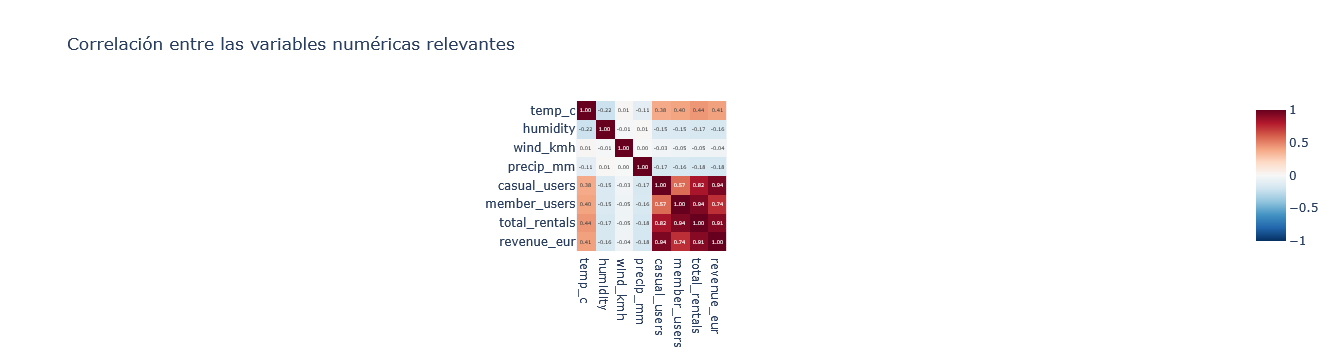

In [30]:
# 1. Un gráfico de correlación entre variables numéricas relevantes
variables = ["temp_c", "humidity", "wind_kmh", "precip_mm", "casual_users", "member_users", "total_rentals", "revenue_eur"]
corr = mobilityData[variables].corr()

fig = px.imshow(corr, text_auto=".2f", color_continuous_scale="RdBu_r", zmin=-1, zmax=1,title="Correlación entre las variables numéricas relevantes")


fig.show()


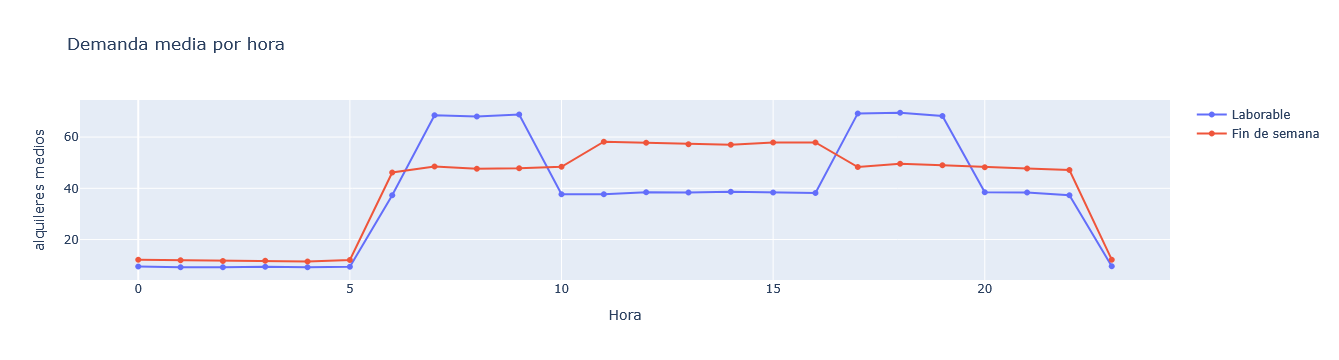

In [32]:
# 2. Un gráfico que muestre la demanda media (total_rentals) por hour (y, si quieres, separando fin de semana / laborable).

# Aplico grouby para generar el grupo y de ahi poder calcular la media
demanda_hora = mobilityData.groupby(["hour", "is_weekend"])["total_rentals"].mean().reset_index()

# por hora 
demanda_hora["tipo_dia"] = demanda_hora["is_weekend"].map(
    {0: "Laborable", 1: "Fin de semana"}) # separando fin de semana / laborable

# dibujo:
fig = px.line(demanda_hora, x="hour", y="total_rentals", color="tipo_dia", markers=True,
              title="Demanda media por hora",
              labels={"hour": "Hora", "total_rentals": "alquileres medios", "tipo_dia": ""})

fig.show()

Las 2 cosas que más me llaman la atención son:
1. En cuanto a las correlaciones: total_rentals está muy correlacionada con 3 variables:
   - member_users (0,94)
   - casual_users (0,82)
   - revenue_eur (0,91)
Tiene sentio porque el total es la suma de usuarios (casual/member) y los ingresos dependen de los alquileres (revenue)
Entre las variables climáticas : la temperatura es la más relacionada (0,44)  lo cual tmabién tiene sentido 0,44 porque más calor suele implicar más alquileres(con buen tiempo me apetece más dalir a montar en bici). En cambio, la lluvia (−0,18) y la humedad (−0,17) tienen un efecto negativo débil, y el viento casi nulo (−0,05) pues son factores menos atractivos para el alquiler de una bici

3. En cuanto al segundo gráfico vemos que las horas puntas:

   - en días laborables : vemos que hay dos picos de 7h a 9h y de 17h a 19h (unos 69 alquileres por hora), que tiene sentido porque es justo idas y venidas del trabajo/univeridad/cole
   - En fin de semana es más contante : la demanda es más alta al mediodía (11h a 16h con unos 58).
   - De madrugada (0 a 5h y 23h) apenas hay alquileres pues la gente está dumiendo
     


## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [36]:
targetVar = "total_rentals"
predictoras = ["hour", "temp_c", "humidity", "wind_kmh", "precip_mm", "is_workingday"]

datos = mobilityData[[targetVar] + predictoras].copy()

print("Nulos", datos.isna().sum())

for col in ["humidity", "wind_kmh"]:
    datos[col] = datos[col].fillna(datos[col].median()) # aplico la mediana

print("Nulos restantes:", datos.isna().sum().sum())

X = datos[predictoras]
y = datos[targetVar]

print("X:", X.shape, "y:", y.shape)

Nulos total_rentals      0
hour               0
temp_c             0
humidity         224
wind_kmh         142
precip_mm          0
is_workingday      0
dtype: int64
Nulos restantes: 0
X: (17520, 6) y: (17520,)


b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [38]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [41]:
lm = LinearRegression()
lm.fit(X_train, y_train)
y_pred_lm = lm.predict(X_test)

r2_lm = r2_score(y_test, y_pred_lm)
mse_lm = mean_squared_error(y_test, y_pred_lm)


print(f"Resultados de regresión lineal : R2 = {r2_lm:.3f} y MSE = {mse_lm:.2f}")

Resultados de regresión lineal : R2 = 0.324 y MSE = 406.32


Vemos que la regresion lineal solo explica el 32,4% de la variación de los alquileres (tien un R² = 0,32) y su MSE es de 404,32. Podemos concluir que es un modelo con resultados mediocres, esperamos un R2 más alto para poder explicar correctamente nuesras varianles y tener un modelo que predice bien.

d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [45]:

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

r2_rf = r2_score(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)

# Para visualizar correctamente la comparación hago un dataframe
comparacion = pd.DataFrame({
    "Modelo": ["Regresión lineal (primero modelo)", "Random Forest(segundo modelo"],
    "R2": [r2_lm, r2_rf], 
    "MSE": [mse_lm, mse_rf],
}).round(2) # redondeo al segundo decimal

comparacion

,Modelo,R2,MSE
0,Regresión lineal (primero modelo),0.3200,406.3200
1,Random Forest(segundo modelo,0.8900,64.2600


Vemos que claramente el random Forest funciona mucho mejor con:
- R² = 0,89 frente a 0,32 (lineal regresion)
- un MSE más bajo de 64 frente a 406 a 64

Porbablemente lo que pase es que la regresión lineal falla porque la relación entre la hora y la demanda no es lineal:  como hemos visto antes hay picos por la mañana y por la tarde. Por lo tanro y una recta no puede representarla correctamente. Sin embargo, Random Forest al combinar muchos árboles si es capaz de ver y modelar esos picos y las interacciones (como por ejemplo que la hora punta solo está en días laborables etc)

## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [48]:
print(mobilityData["high_demand"].value_counts())   #balance de clases 

mobilityData["high_demand"].value_counts(normalize=True).round(3)  

high_demand
0    12071
1     5449
Name: count, dtype: int64


Hago la proporción para ver si como están de balanceadas (porq ya veo que hay un problema)


In [50]:
mobilityData["high_demand"].value_counts(normalize=True).round(3)

high_demand
0   0.6890
1   0.3110
Name: proportion, dtype: float64

Vemos que las clases están desbalanceadas el 31% de las horas son de alta demanda y el resto (69%) no. Esto es importante tenerlo en cuenta

b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [54]:
predictoras_c = ["hour", "temp_c", "humidity", "wind_kmh", "precip_mm", "is_workingday", "is_weekend"]

datos_c = mobilityData[["high_demand"] + predictoras_c].copy()
for col in ["humidity", "wind_kmh"]:
    datos_c[col] = datos_c[col].fillna(datos_c[col].median())

X_c = datos_c[predictoras_c]
y_c = datos_c["high_demand"]


X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_c, y_c, test_size=0.3, random_state=42, stratify=y_c)

logit = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000)),
])


logit.fit(X_train_c, y_train_c)

y_pred_c = logit.predict(X_test_c)

c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


Accuracy: 0.752


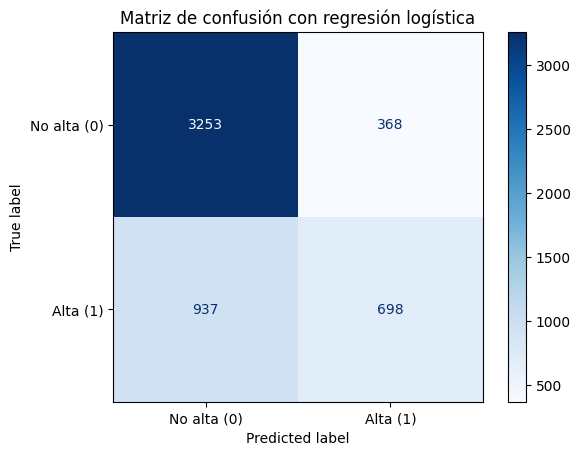

In [56]:
acc = accuracy_score(y_test_c, y_pred_c)

print(f"Accuracy: {acc:.3f}")

cm = confusion_matrix(y_test_c, y_pred_c)
ConfusionMatrixDisplay(cm, display_labels=["No alta (0)", "Alta (1)"]).plot(cmap="Blues")
plt.title("Matriz de confusión con regresión logística")
plt.show()

El modelo acierta un 75,2 % de los casos pero en la matriz de confusión se ve que falla bastante con la clase 1 pues de las 1.635 horas de alta demanda solo detecta 698 (q es menos de la mitad). Pues hemos dicho antes que las clases están algo desbalanceadas (69 % fente 31 %) lo que hace que el modelo tienda a predecir 0

d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


,variable,coeficiente
4,precip_mm,-0.9610
1,temp_c,0.7670
6,is_weekend,0.4070
0,hour,0.3710
2,humidity,-0.2460
3,wind_kmh,-0.1570
5,is_workingday,0.1540


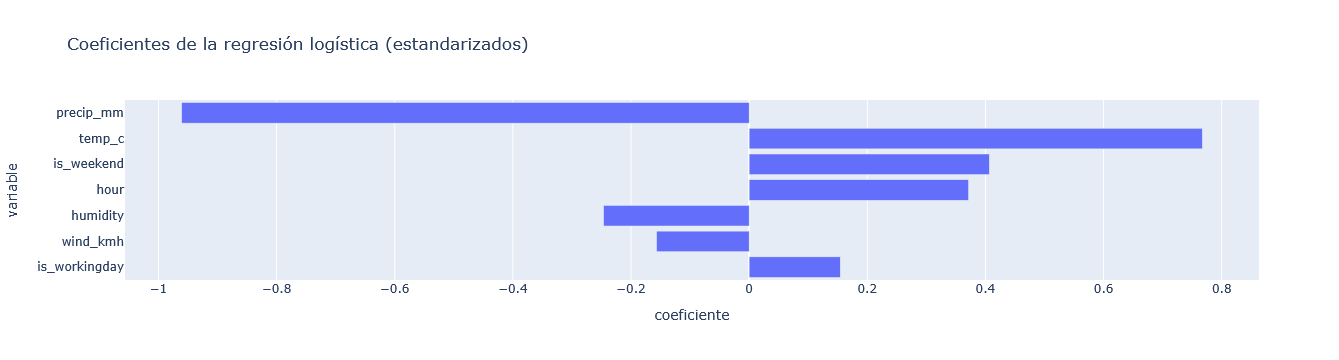

Accuracy Random Forest: 0.878


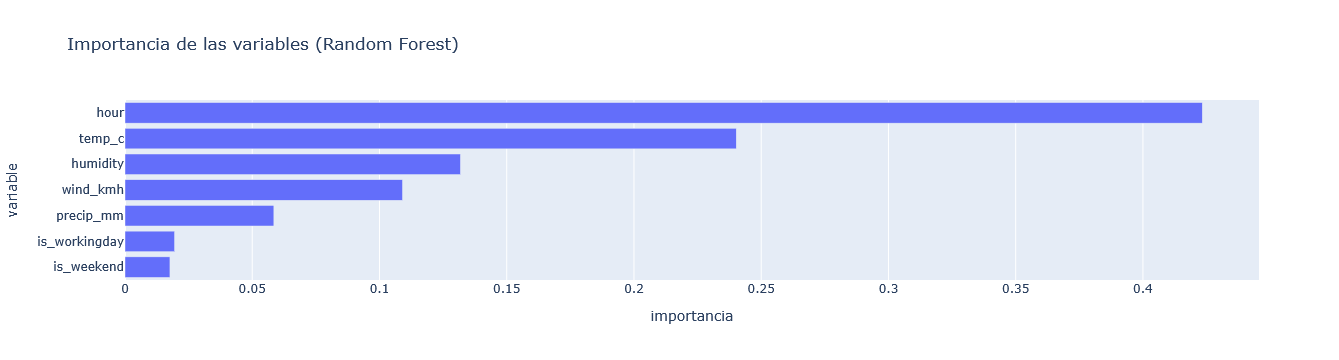

In [57]:
# Ademas de lo ya visto en el ejercicio 2: Para evaluarlo bien uso el grafico visto en clase que nos da la importancia de las varibles en los modelos para rf y
# para la regresion logistica ordeno el valor absolto de los coeficientes de las variablles


coeficientes = pd.DataFrame({
    "variable": predictoras_c,
    "coeficiente": logit.named_steps["model"].coef_[0],
})

coeficientes["abs"] = coeficientes["coeficiente"].abs()
coeficientes = coeficientes.sort_values("abs", ascending=False)
display(coeficientes[["variable", "coeficiente"]].round(3))

fig = px.bar(coeficientes.sort_values("abs"), x="coeficiente", y="variable", orientation="h",
             title="Coeficientes dee regresión logística")

fig.show()

rfc = RandomForestClassifier(n_estimators=100, random_state=42)
rfc.fit(X_train_c, y_train_c)

print(f"Accuracy Random Forest: {accuracy_score(y_test_c, rfc.predict(X_test_c)):.3f}")

importancias = pd.DataFrame({"variable": predictoras_c, "importancia": rfc.feature_importances_})
fig = px.bar(importancias.sort_values("importancia"), x="importancia", y="variable", orientation="h",
             title="Importancia de las variables (Random Forest)")
fig.show()

Con los coeficientesCde la logística vemos que los factores más asociados a la alta demanda son :
- lluvia(−0,96: tiene sentido pues a más precipitación menos probabilidad de alta demanda; no quieres alquilar una bici
- temperatura (+0,77: más calor, más demanda)

El Random Forest (que era mejor modelo) da como variable más importante la hora (42%), seguida de la temperatura (24%) lo cual concuerda con el gráfico del ejercicio 2 enel que vimos la demanda dependía mucho de las horas punta pero de forma no lineal (con picos que suben y bajan  a lo largo del día)
Asi que : hora, temperatura y lluvia son los factores clave.

## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



El factor más importante es la hora del día es la variable con más peso en los dos Random Forest. Lo vimos en el ejercico 2 que en días laborables hay dos picos claros, de 7h a 9h y de 17 a 19h que corresponden a los desplazamientos al trabajo/Colegio/universidad.
En fin de semana la demanda es más plana y se concentra entre las 11h y las 16. 

El segundo factor es el clima. Un factor que claaramente va a afectar a montar o no en bici (al aire libre):  la temperatura tiene una correlación positiva con la demanda y en verano se alquila casi el doble que en invierno (tema frio, luz etc) mientras que la lluvia la reduce mucho.

En cuanto la mejor modelo: Random Forest (R² = 0,89) supera claramente a la regresión lineal (R² = 0,32) (clasifiacion tb) y la razón es que la relación con la hora no es lineal sino que la demanda sube y baja

Añdiria más datos como el precio que algo que mueve mucho o datos de otras ciudades,